Initialising of libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Loading the datasets

In [4]:
inventory=pd.read_csv('inventory.csv')
sales=pd.read_csv('sales.csv')
inventory.head()

,title,author,genre,price,quantity
0,Hidden Patterns in Quantum Worlds,Isabel Shah,Science,14.43,6
1,A History of the Ottomans,Chloe Brooks,History,29.64,29
2,Shadow over Midnight Train,Noah Okafor,Mystery,11.72,6
3,Beyond the Harbor,Oliver Fischer,Fiction,16.98,11
4,Roads to Revolution,Sofia Brooks,History,14.95,24


In [5]:
sales.head()

,date,title,quantity_sold,total_revenue
0,2026-07-16,Shadow over Midnight Train,4,46.88
1,2026-07-16,Daily Habits for Resilience,2,24.78
2,2026-07-16,Max and the Rainy Day,1,8.38
3,2026-07-17,Orbit of Andromeda,3,57.48
4,2026-07-17,Beyond Andromeda,1,14.56


Data cleaning

In [6]:
inventory.isnull().sum()

,0
title,0
author,0
genre,0
price,0
quantity,0


In [7]:
sales.isnull().sum()

,0
date,0
title,0
quantity_sold,0
total_revenue,0


In [8]:
sales['date']=pd.to_datetime(sales['date'])
inventory['price']=inventory['price'].fillna(inventory['price'].mean())
inventory['quantity']=inventory['quantity'].fillna(0)
inventory['genre']=inventory['genre'].fillna(inventory['genre'].mode()[0])

Bookstore class (add, update, sell, report)

In [9]:
class Bookstore:
    def __init__(self,inventory,sales):
        self.inventory=inventory
        self.sales=sales

    def add_book(self,title,author,price,quantity,genre='Unknown'):
        if price<=0 or quantity<=0:
            print('Price and quantity must be positive')
            return
        if title in self.inventory['title'].values:
            print('Book already exists')
            return
        self.inventory.loc[len(self.inventory)]=[title,author,genre,price,quantity]
        print('Book added:',title)

    def update_inventory(self,title,quantity):
        if title not in self.inventory['title'].values:
            print('Book not found')
            return
        if quantity<0:
            print('Quantity cannot be negative')
            return
        self.inventory.loc[self.inventory['title']==title,'quantity']=quantity
        print('Stock updated for',title)

    def record_sale(self,title,quantity):
        if title not in self.inventory['title'].values:
            print('Book not found')
            return
        if quantity<=0:
            print('Quantity must be positive')
            return
        row=self.inventory[self.inventory['title']==title].iloc[0]
        if quantity>row['quantity']:
            print('Not enough stock. Only',row['quantity'],'left')
            return
        self.inventory.loc[self.inventory['title']==title,'quantity']-=quantity
        new_sale={'date':pd.Timestamp.today().normalize(),'title':title,'quantity_sold':quantity,'total_revenue':round(row['price']*quantity,2)}
        self.sales=pd.concat([self.sales,pd.DataFrame([new_sale])],ignore_index=True)
        print('Sale recorded for',title)

    def generate_report(self):
        print('Total books in catalogue:',len(self.inventory))
        print('Total stock:',self.inventory['quantity'].sum())
        print('Total revenue:',self.sales['total_revenue'].sum())
        print('Total units sold:',self.sales['quantity_sold'].sum())
        best=self.sales.groupby('title')['quantity_sold'].sum().idxmax()
        print('Best selling book:',best)

Testing the class

In [10]:
store=Bookstore(inventory.copy(),sales.copy())
store.add_book('Python for Everyone','Pujan',19.99,25,'Technology')
store.update_inventory('Python for Everyone',30)
store.record_sale('Python for Everyone',3)
store.record_sale('Python for Everyone',500)
store.add_book('Bad Book','Someone',-5,10)
store.generate_report()

Book added: Python for Everyone
Stock updated for Python for Everyone
Sale recorded for Python for Everyone
Not enough stock. Only 27 left
Price and quantity must be positive
Total books in catalogue: 201
Total stock: 2503
Total revenue: 8399.34
Total units sold: 468
Best selling book: Bella and the Sleepy Dragon


Sales analysis using NumPy

In [11]:
df=sales.merge(inventory,on='title')
df['month']=df['date'].dt.month
total_revenue=np.sum(df['total_revenue'])
print('Total revenue:',total_revenue)

Total revenue: 8339.369999999999


In [12]:
average_price=np.mean(inventory['price'])
print('Average price:',average_price)

Average price: 16.965


In [13]:
monthly_revenue=df.groupby('month')['total_revenue'].sum()
growth_rate=np.diff(monthly_revenue.values)/monthly_revenue.values[:-1]*100
print(growth_rate)

[139.19515684 -41.50523095 -30.52040423]


Sales analysis using Pandas

In [14]:
best_selling=df.groupby('title')['quantity_sold'].sum().sort_values(ascending=False)
print(best_selling.head(10))

title
Bella and the Sleepy Dragon     11
Flavors of Weeknight Meals      11
Simple Route                    11
Shadow over Manor House         11
Unlock Confidence               11
Practical Web Development       10
Understanding Quantum Worlds    10
The Art of Deep Work            10
Orbit of Andromeda               9
Wonders of the Cosmos            9
Name: quantity_sold, dtype: int64


In [15]:
genre_sales=df.groupby('genre')['total_revenue'].sum().sort_values(ascending=False)
print(genre_sales)

genre
Technology         1628.04
Cooking            1098.72
Science            1033.67
Biography           930.32
Mystery             865.08
Science Fiction     716.27
Self-Help           672.43
History             463.07
Romance             319.31
Children            248.27
Fantasy             202.23
Fiction             161.96
Name: total_revenue, dtype: float64


In [16]:
author_sales=df.groupby('author')['total_revenue'].sum().sort_values(ascending=False)
print(author_sales.head(10))

author
Oliver Fischer    509.36
Leila Carter      368.59
Felix Shah        362.29
Meera Dubois      340.32
Victor Rossi      326.26
Rahul Moreau      297.01
Aisha Bauer       287.26
Zara Walker       274.78
Elena Alvarez     253.93
Tara Novak        240.67
Name: total_revenue, dtype: float64


In [17]:
revenue_share=genre_sales/genre_sales.sum()*100
print(revenue_share)

genre
Technology         19.522338
Cooking            13.175096
Science            12.395061
Biography          11.155759
Mystery            10.373445
Science Fiction     8.589018
Self-Help           8.063319
History             5.552818
Romance             3.828946
Children            2.977083
Fantasy             2.425003
Fiction             1.942113
Name: total_revenue, dtype: float64


Bar chart - Total sales by genre

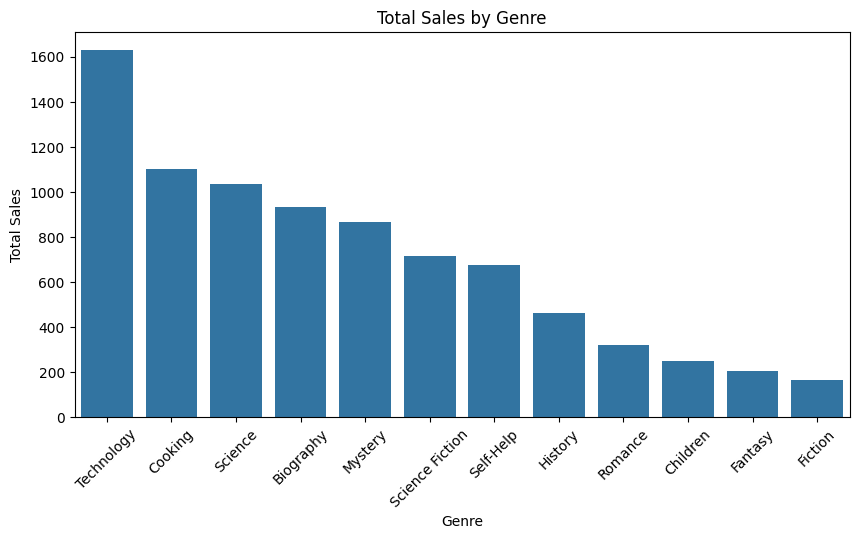

In [18]:
plt.figure(figsize=(10,5))
sns.barplot(x=genre_sales.index,y=genre_sales.values)
plt.xticks(rotation=45)
plt.xlabel('Genre')
plt.ylabel('Total Sales')
plt.title('Total Sales by Genre')
plt.show()

Bar chart - Total sales by author (top 10)

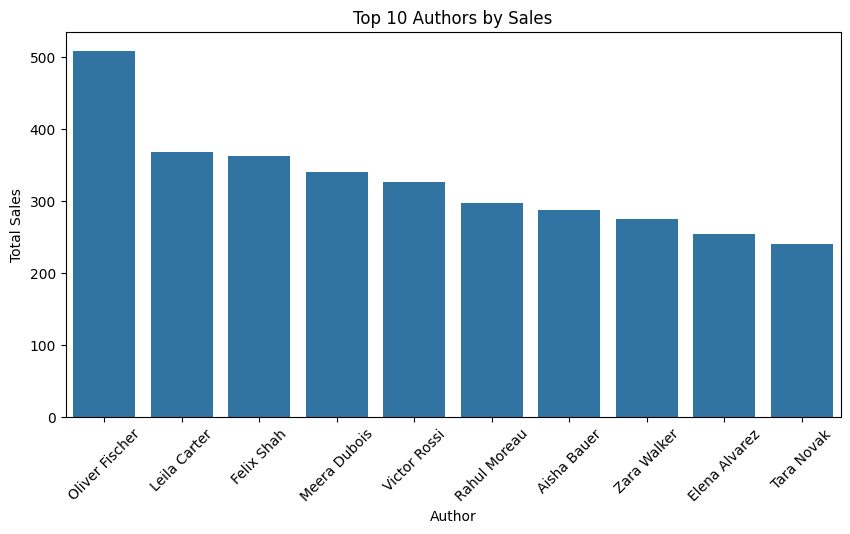

In [19]:
plt.figure(figsize=(10,5))
sns.barplot(x=author_sales.head(10).index,y=author_sales.head(10).values)
plt.xticks(rotation=45)
plt.xlabel('Author')
plt.ylabel('Total Sales')
plt.title('Top 10 Authors by Sales')
plt.show()

Line graph - Monthly sales trends

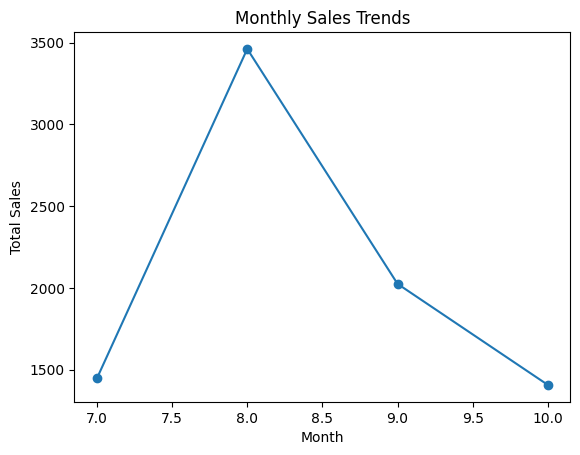

In [20]:
plt.plot(monthly_revenue.index,monthly_revenue.values,marker='o')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Monthly Sales Trends')
plt.show()

Pie chart - Revenue share by genre

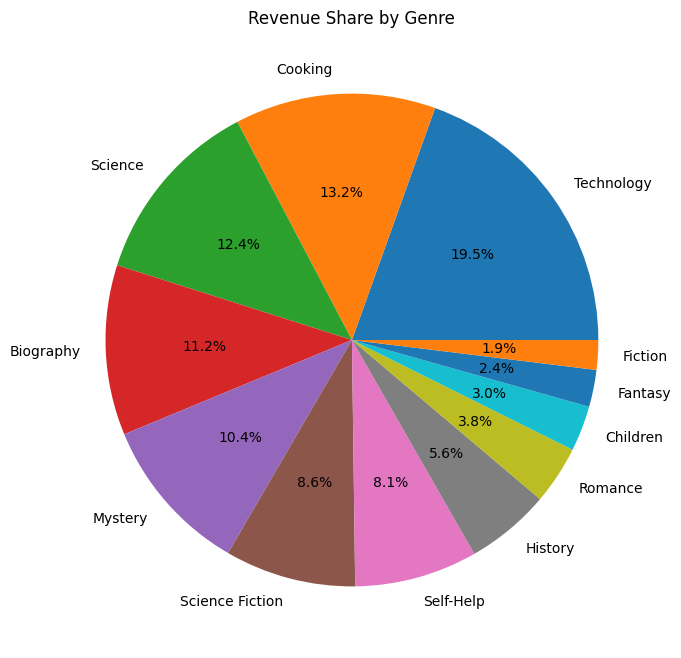

In [21]:
plt.figure(figsize=(8,8))
plt.pie(genre_sales,labels=genre_sales.index,autopct='%1.1f%%')
plt.title('Revenue Share by Genre')
plt.show()

Heatmap - Correlation between price and sales volume

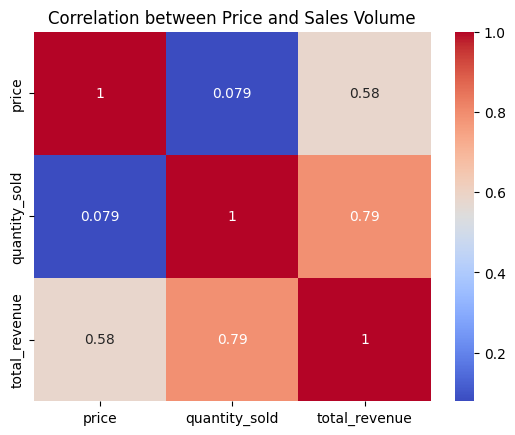

In [22]:
per_book=df.groupby('title').agg({'price':'first','quantity_sold':'sum','total_revenue':'sum'})
sns.heatmap(per_book.corr(),annot=True,cmap='coolwarm')
plt.title('Correlation between Price and Sales Volume')
plt.show()